In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
# import the iris dataset
from sklearn.datasets import load_iris
# import the KNeighborsClassifier class from sklearn
from sklearn.neighbors import KNeighborsClassifier
# import metrics model to check the accuracy 
from sklearn import metrics
# import train-test-split function from sklearn
from sklearn.model_selection import train_test_split

"Iris" -- https://archive-beta.ics.uci.edu/dataset/53/iris

A small classic dataset from Fisher, 1936. One of the earliest known datasets used for evaluating classification methods. This is one of the earliest datasets used in the literature on classification methods and widely used in statistics and machine learning.  The data set contains 3 classes of 50 instances each, where each class refers to a type of iris plant.  One class is linearly separable from the other 2; the latter are not linearly separable from each other.

Predicted attribute: class of iris plant.

In [6]:
iris = load_iris()
# data, target_names, target, feature_names
print(iris.feature_names)  # try print(iris.data), print(iris.feature_names), etc.

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


Text(0.5, 0, 'sepal length (cm)')

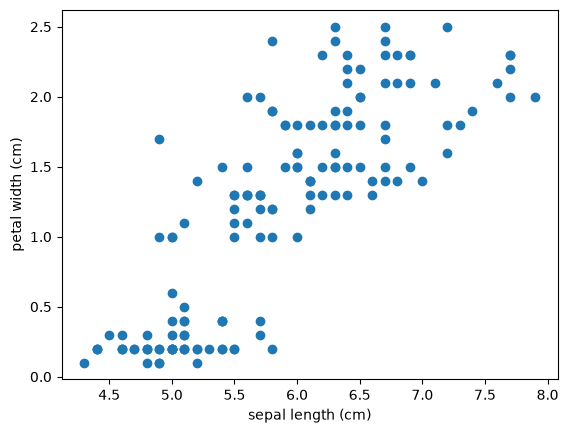

In [7]:
# take a first look at the data
plt.plot(iris.data[:,0], iris.data[:,3], 'o') # we know what column 0 and column 3 are from the step above.
plt.ylabel(iris.feature_names[3])
plt.xlabel(iris.feature_names[0])

Text(0.5, 0, 'sepal length (cm)')

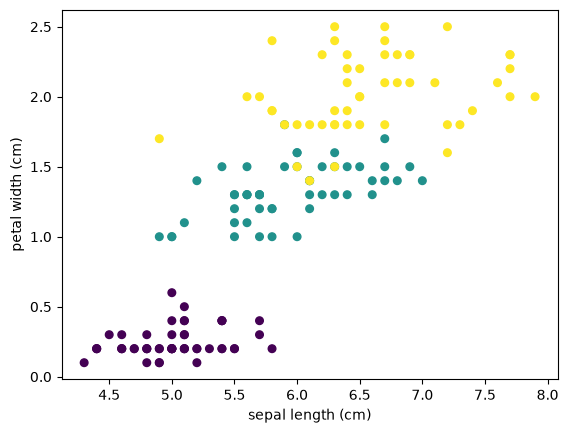

In [8]:
# take another look at the data, this time color-coded by species
plt.scatter(iris.data[:,0], iris.data[:,3], s = 30, c = iris.target) # c = iris.target is the part that does the color coding
plt.ylabel(iris.feature_names[3])
plt.xlabel(iris.feature_names[0])

In [9]:
# Feature matrix (inputs) in an object named X
X = iris.data
# Response vector (output or target) in a object named y
y = iris.target

print(np.shape(X))
print(np.shape(y))

(150, 4)
(150,)


In [10]:
# Split iris data in train and test data (80:20)
# Set the random state to =4 to be reproducible.
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=4)

In [11]:
#check the shape of train and test objects
print(X_train.shape)
print(X_test.shape)

(120, 4)
(30, 4)


In [12]:
# Try running from k=1 through 25 and record testing accuracy
# k is one the model parameters that you can tune to improve the model
k_range = range(1,26)

# initialize empty list to save the accuracy score for each value of k
scores = {}
scores_list = []

# iterate over the range of k values to assess which model preforms best
for k in k_range:
    
        # build the model based on the training data and the given value of k
        knn = KNeighborsClassifier(n_neighbors=k)
        knn.fit(X_train,y_train)
        
        # predict results from the test data using the model constructed in the previous step
        y_pred=knn.predict(X_test)
        
        # compare the predicted result to the actual value to assess model performance
        scores[k] = metrics.accuracy_score(y_test,y_pred)
        scores_list.append(metrics.accuracy_score(y_test,y_pred))

Text(0, 0.5, 'accuracy score')

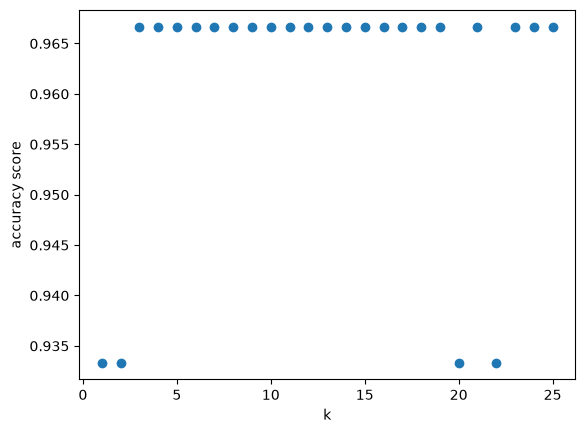

In [13]:
# plot the model accuracy for each value of k
plt.scatter(k_range,scores_list)
plt.xlabel('k')
plt.ylabel('accuracy score')

In [14]:
# based on the accuracy achieved above, let's try using k = 8
# here we build a model based on ALL of the data to apply to other data 
# (i.e. not from the test or training set)
knn = KNeighborsClassifier(n_neighbors=8)
knn.fit(X,y)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",8
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [15]:
# here we apply the new model built above to 'new' data

#0 = setosa, 1=versicolor, 2=virginica
classes = {0:'setosa',1:'versicolor',2:'virginica'}

# Make a prediction for the 'new' data 
# predict for the below two random observations
x_new = [[3,4,5,2], # first observation
         [5,4,2,2]] # second observation

y_predict = knn.predict(x_new)

# Is this what we get with the neural network classifier?
print(classes[y_predict[0]])  # y_predict[0] made a prediction. Executing classes[1] returns what class it thinks this iris is.
print(classes[y_predict[1]])  # y_predict[1] made a prediction. Executing classes[0] returns what class it thinks this iris is.

versicolor
setosa


Text(0.5, 0, 'sepal width (cm)')

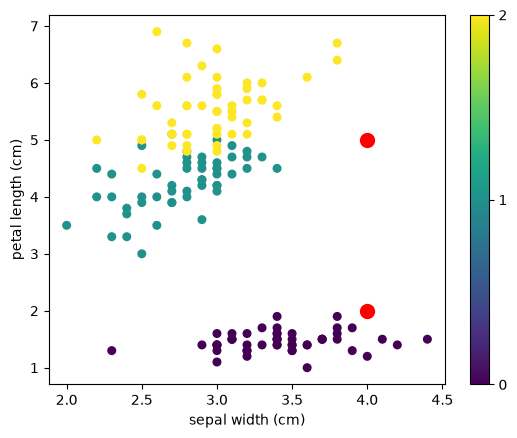

In [16]:
plt.scatter(iris.data[:,1], iris.data[:,2], s = 30, c = iris.target)
plt.colorbar(ticks=[0, 1, 2])
plt.plot(np.array(x_new)[:,1], np.array(x_new)[:,2], 'or', markersize = 10)
plt.ylabel(iris.feature_names[2])
plt.xlabel(iris.feature_names[1])